# 05-URDF机械臂建模


## 1. 本篇范围与建模目标

上一篇说明了为什么先在仿真中开发和测试机械臂。本篇开始解决模型描述问题：怎样告诉计算机，机械臂有哪些部件、部件怎样连接，以及每个关节能怎样运动？

课件先用人体结构作类比：躯干连接脖子，脖子连接头部。描述机械臂时，同样需要说明部件、连接关系和属性，但还要使用计算机可以读取的标准格式。

本篇依据 `具身智能实战02.pptx` 第 **39—61 页**整理，保留课程的讲解顺序：URDF 的用途、连杆与关节、树状结构、父子关系，再到 XML 标签和参数示例。

第 61 页只有“实战：机械臂 urdf 从零到一”的标题，没有完整模型、项目文件或加载步骤。本篇完整整理 PPT 中已有的概念与代码片段，不将它们写成已经完成的实战项目。


## 2. URDF：描述机器人的统一格式

**URDF（Unified Robot Description Format，统一机器人描述格式）**是一种基于 XML 的机器人描述格式。课件将它称为机器人世界的“解剖学语言”。

它把机器人结构写成文件，主要描述：

- 机器人由哪些刚性部件组成。
- 部件之间怎样连接，允许怎样运动。
- 部件的外观、碰撞形状以及质量、惯性等属性。

这里涉及两类模型：**运动学模型**关注结构与运动关系，**动力学模型**还需要质量、惯性等影响受力和运动响应的属性。

### 2.1 “统一”带来的价值

课件列出 ROS、Gazebo、PyBullet、Isaac Sim、MuJoCo 和 Three.js，说明同一份机器人描述可以在不同工具中复用，减少重复定义模型的工作。

> **补充说明：**不同工具对 URDF 的支持范围和导入方式有差异，有的需要加载器、转换或额外配置。Three.js 本身是三维渲染库，加载 URDF 需要相应工具。能导入同一份文件，也不代表各平台自动拥有完全一致的碰撞、动力学和控制行为。

本节先建立统一描述的基础，PPT 没有在这些页中指定具体加载器或启动命令。


## 3. 连杆与关节

URDF 的结构由 **Link（连杆）**和 **Joint（关节）**组成。课件使用人体与机械臂的对照图帮助理解。

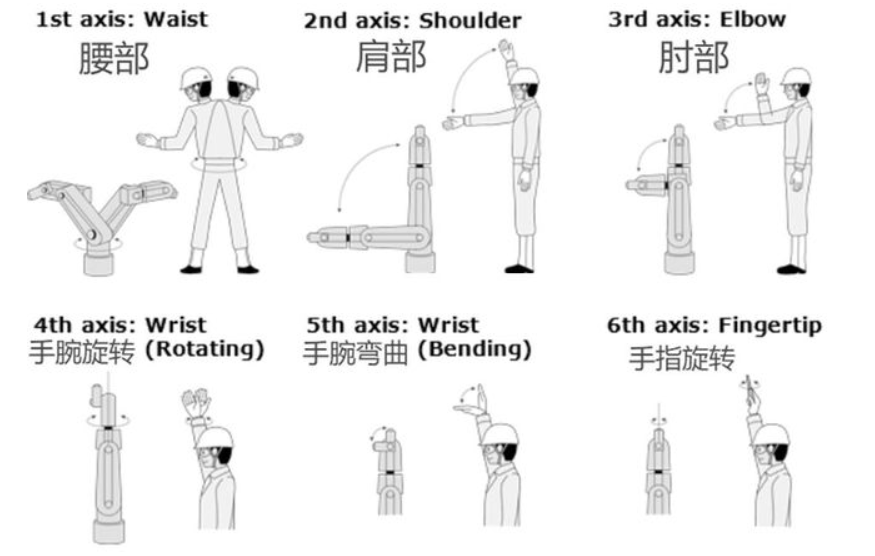

### 3.1 Link：刚性实体

课件把机器人中刚性的、在模型中不发生形变的部件称为 Link。它可以对应基座、上臂、小臂或末端工具等实体部分。

人体类比中，Link 类似骨骼。这个词并不限于细长的“杆”，基座等刚性部件同样可以定义为 Link。

### 3.2 Joint：连接与运动关系

Joint 描述两个 Link 之间的连接，以及它们允许怎样相对运动。

例如，肘关节连接上臂与小臂，并规定小臂相对于上臂绕哪个方向旋转、能够转到什么范围。

| 元素 | 主要描述内容 | 人体类比 |
|---|---|---|
| Link | 刚性部件及其属性 | 上臂、小臂等骨骼 |
| Joint | 部件之间的连接与运动方式 | 肘关节、腕关节 |

图中的六轴动作用于类比关节方向，不表示本课程的模型一定具有相同数量和布局的关节。


## 4. 模型必须形成树状结构

课件第 46 页强调：一系列 Link 通过 Joint 连接成**树状结构（Tree Structure）**，需要有一个根 Link，且不允许出现闭环。

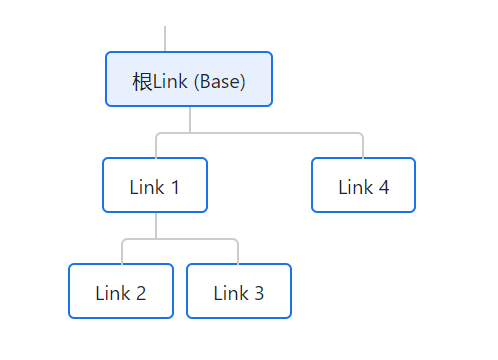

从根 Link 出发，可以逐层找到它连接的其他部件。图中根节点下面有不同分支，说明 URDF 可以描述分叉结构，不只适用于一条直链。

> **补充说明：**在普通 URDF 树中，根 Link 没有父关节，其余每个 Link 通过一个关节连接到父 Link。一个父 Link 可以连接多个子 Link，但同一个子 Link 不能同时有两个父关节。

“不允许闭环”意味着连接关系不能绕一圈回到同一个 Link。真实机械机构可能存在闭环，但需要借助具体工具的其他建模机制处理，不能直接当作普通 URDF 树来定义。

还要区分两个“根”：**根 Link**是机器人结构中的根部件，后面介绍的 **`<robot>` 根标签**是 XML 文件最外层的元素。


## 5. 父子关系与运动学链

每个 Joint 连接一个父 Link（Parent Link）和一个子 Link（Child Link）。这种关系明确了我们从哪个部件出发，描述另一个部件的位置和运动。

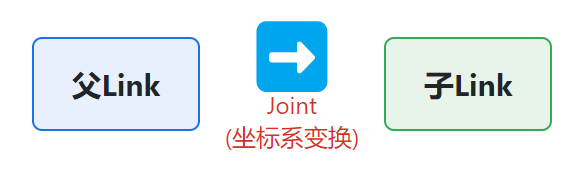

课件使用肘关节举例：

- 上臂是父 Link。
- 小臂是子 Link。
- 肘关节描述小臂相对于上臂的安装位置和运动方式。

从根 Link 开始，父子关系一级一级传递，构成**运动学链（Kinematic Chain）**。机械臂的各段位置与运动，因此能够沿连接关系逐层描述。

到这里，课件的结构模型可以概括为：刚性实体写成 Link，连接与运动写成 Joint，再通过父子关系组成无闭环的树。


## 6. `<robot>`：文件的根标签

所有 URDF 定义放在一个 `<robot>` 标签内部，`name` 属性给机器人命名。

课件第 51 页的文件框架如下，已整理为正常 XML 格式：

```xml
<?xml version="1.0"?>
<robot name="simple_robotic_arm">
  <!-- 所有的 links 和 joints 都将在这里定义 -->
</robot>
```

`simple_robotic_arm` 是课程示例的机器人名称。这个框架还没有定义任何部件，只展示文件的外层结构。

> **课件格式修正：**PPT 的部分代码写成 `<robotname="...">`、`<linkname="...">`、`<parentlink="..."/>`，标签名与属性之间缺少空格。本篇统一补齐必要空格并整理缩进，保留课件的名称、参数和关键注释。标签名和属性名仍分别是 `robot` 与 `name`、`parent` 与 `link`，不能连成一个名字。


## 7. `<link>`：定义刚性部件

每个 Link 用 `<link>` 定义，并使用唯一的 `name` 标识。后面的关节会通过这个名称引用它。

课件第 52 页给出下面的结构示意，其中 `...` 表示尚未展开的内容：

```xml
<link name="base_link">
  <!-- 视觉、碰撞、惯性属性 -->
  <visual> ... </visual>
  <collision> ... </collision>
  <inertial> ... </inertial>
</link>
```

| 子标签 | 负责什么 | 使用者 |
|---|---|---|
| `<visual>` | 外观形状、颜色等 | 渲染器 |
| `<collision>` | 碰撞检测使用的形状 | 碰撞检测与物理引擎 |
| `<inertial>` | 质量、质心和惯性等 | 动力学计算 |

三种属性分别服务于不同目的。一个部件看起来形状正确，不能据此判断它的碰撞体和动力学参数也已经正确。

上面的代码只用于阅读结构，不能把省略号当作完整模型定义直接加载。


## 8. `<visual>`：外观、位置与材质

`<visual>` 定义 Link 看起来是什么样子。课件强调，它负责渲染，不直接定义碰撞或惯性。

| 子标签 | 含义 |
|---|---|
| `<geometry>` | 外观几何体，可以使用 `<box>`、`<cylinder>` 或外部模型 `<mesh>` |
| `<origin>` | 外观几何相对于 Link 坐标系的位置 `xyz` 和姿态 `rpy` |
| `<material>` | 外观的颜色或纹理 |

课件第 53 页使用圆柱示例：

```xml
<visual>
  <geometry>
    <cylinder length="0.1" radius="0.05"/>
  </geometry>
  <origin xyz="0 0 0.05" rpy="0 0 0"/>
  <material name="grey">
    <color rgba="0.5 0.5 0.5 1"/>
  </material>
</visual>
```

逐项理解：

- 圆柱长度为 `0.1 m`，半径为 `0.05 m`。
- 外观原点相对于 Link 原点沿 Z 方向移动 `0.05 m`。
- `rpy="0 0 0"` 表示没有额外旋转。
- 材质名称为 `grey`，`rgba` 的四个数分别表示红、绿、蓝与透明度。`0.5 0.5 0.5 1` 表示不透明的灰色。

> **补充说明：**URDF 的圆柱默认沿自身 Z 轴、以中心为原点。这个例子向上平移半个长度，因此圆柱在 Link 坐标系中的下端位于 `z=0`，上端位于 `z=0.1 m`。外观的平移只改变它在 Link 中的摆放，不改变整个 Link 与其他部件的连接。


## 9. `<collision>`：碰撞检测的形状

`<collision>` 定义物理引擎用于计算碰撞的几何形状。它与屏幕上显示的外观模型有不同用途。

课件指出，为提高计算效率，碰撞体通常采用比视觉模型更简单的几何形状。外观可以保留较多细节，碰撞体则重点表达与接触、碰撞有关的体积。

课件第 54 页只讲解用途，没有给出具体 XML 片段。

> **补充说明：**碰撞体通常不会作为正常外观显示，但一些工具可以开启碰撞调试视图。看到视觉模型，不代表已经定义碰撞体；实际碰撞效果还取决于仿真工具的设置和支持方式。


## 10. `<inertial>`：质量、质心与惯性

`<inertial>` 描述 Link 的动力学属性。课件依次介绍质量、惯性张量和质心位置。

| 标签或属性 | 含义 |
|---|---|
| `<mass value="..."/>` | 质量，单位为 `kg` |
| `<inertia .../>` | 惯性张量，描述质量分布对旋转的影响 |
| `<origin>` | 质心相对于 Link 坐标系的位置 |

课件第 55 页的惯性参数示例为：

```xml
<inertial>
  <mass value="0.1"/>
  <inertia ixx="0.01" iyy="0.01" izz="0.01"
           ixy="0" ixz="0" iyz="0"/>
</inertial>
```

其中质量为 `0.1 kg`，惯性张量的对角项为 `ixx`、`iyy`、`izz`，其余三个参数为非对角项。课件用“旋转的难易程度”帮助初步理解惯性。

课件区分了两种使用情况：仅观察结构与运动关系的运动学仿真，可以忽略或简化动力学属性；涉及力、力矩和运动响应的动力学仿真，则需要这些属性。

> **补充说明：**惯性张量的单位为 `kg·m²`，并在惯性坐标系中表达。`<inertial>` 内的 `origin` 还可以用 `rpy` 描述该坐标系的方向。本例没有写 `origin`，按 URDF 默认值取零平移和零旋转，质心位于 Link 原点。课件数值用于说明标签，不能直接当作真实部件的测量值。

上一节的圆柱外观与这里的惯性参数是分别展示的代码片段，PPT 没有给出它们之间的物理计算或校准关系。


## 11. `<joint>`：完整的连接与运动示例

课件第 56 页给出一个旋转关节。它将 `arm1_link` 连接到 `base_link`：

```xml
<joint name="joint1" type="revolute">
  <parent link="base_link"/>
  <child link="arm1_link"/>
  <origin xyz="0 0 0.1" rpy="0 0 0"/>
  <axis xyz="0 0 1"/>
  <limit lower="-1.57" upper="1.57"
         effort="10" velocity="1.0"/>
</joint>
```

| 项目 | 示例值 | 描述内容 |
|---|---|---|
| `name` | `joint1` | 关节名称 |
| `type` | `revolute` | 有角度限制的单轴旋转关节 |
| `parent` | `base_link` | 父 Link 的名称 |
| `child` | `arm1_link` | 子 Link 的名称 |
| `origin` | `xyz="0 0 0.1"` | 关节在父 Link 坐标系中的安装位置 |
| `axis` | `xyz="0 0 1"` | 在关节坐标系中沿 Z 轴定义运动轴 |
| `limit` | 角度、力矩与速度参数 | 关节的运动及能力限制 |

这是一个关节片段。使用时需要放在 `<robot>` 内，并保证 `base_link` 和 `arm1_link` 都已经被定义。


## 12. `type`：四种关节类型

课件第 57 页介绍四种常用类型：

| `type` 值 | 运动方式 | 课件例子 |
|---|---|---|
| `revolute` | 绕单轴旋转，并具有角度限制 | 肘关节 |
| `prismatic` | 沿单轴平移 | 伸缩臂 |
| `fixed` | 父子 Link 之间没有相对运动 | 固定连接 |
| `continuous` | 绕单轴连续旋转，没有角度位置限制 | 轮子 |

`revolute` 与 `continuous` 都是旋转关节，区别在于是否有位置上下限。`fixed` 仍然描述两个部件之间的连接和安装关系，只是不增加运动自由度。

> **补充说明：**连续旋转没有角度上下限，不表示力矩和速度也没有限制。URDF 中 `continuous` 关节仍可描述 `effort` 与 `velocity` 限制。


## 13. `parent`、`child` 与关节 `origin`

课件第 58 页进一步解释三个标签：`parent` 和 `child` 明确连接关系，`origin` 确定关节的安装位置与姿态。

在 `joint1` 示例中，关节相对于 `base_link` 沿 Z 方向安装在 `0.1 m` 处，并且没有额外旋转。

```xml
<parent link="base_link"/>
<child link="arm1_link"/>
<origin xyz="0 0 0.1" rpy="0 0 0"/>
```

### 13.1 理解静态安装与关节运动

PPT 将关节 `origin` 简化解释为“子 Link 坐标系相对于父 Link 坐标系的静态位姿”。

> **坐标系补充说明：**更准确地说，关节 `origin` 描述父 Link 坐标系到关节坐标系的固定变换。子 Link 坐标系在关节零位置时与关节坐标系重合；对于可动关节，子 Link 相对于父 Link 的实际位姿还会随关节位置变化。`origin` 保存安装关系，当前关节角度或位移另行决定运动状态。

这可以避免把 `xyz="0 0 0.1"` 理解为“无论关节怎样运动，整个子部件都保持原来的位姿”。

### 13.2 同名 `origin` 的参照对象不同

| `origin` 所在位置 | 相对于哪个坐标系 | 描述什么 |
|---|---|---|
| `<visual>` 内 | 当前 Link 坐标系 | 外观几何的摆放 |
| `<collision>` 内 | 当前 Link 坐标系 | 碰撞几何的摆放 |
| `<inertial>` 内 | 当前 Link 坐标系 | 质心位置与惯性坐标系方向 |
| `<joint>` 内 | 父 Link 坐标系 | 关节的固定安装位姿 |

> **单位补充说明：**`xyz` 按 X、Y、Z 顺序给出平移，单位为米；`rpy` 按 roll、pitch、yaw 顺序给出绕 X、Y、Z 的姿态角，单位为弧度。相同数字放在不同层级的 `origin` 中，含义会随参照对象改变。


## 14. `axis` 与 `limit`：运动方向和边界

### 14.1 `axis` 使用关节坐标系

课件第 59 页说明，`axis` 为旋转关节或移动关节定义运动轴方向。例如：

```xml
<axis xyz="0 0 1"/>
```

对于旋转关节，它表示绕关节 Z 轴旋转；对于移动关节，它表示沿关节 Z 轴平移。

> **坐标系补充说明：**这里的方向在关节坐标系中表达。PPT 使用“即子 Link 坐标系”的说法，应结合前一节的零位置关系理解，不能直接把它当作世界坐标系的 Z 轴。如果关节 `origin` 带有旋转，运动轴在父坐标系或世界坐标系中的方向也会随之改变。`axis` 描述方向，`origin` 才描述安装位置。

### 14.2 `limit` 的参数与单位

课件的关节范围片段为：

```xml
<joint name="joint1" type="revolute">
  <!-- 定义运动轴 -->
  <axis xyz="0 0 1"/>
  <!-- 定义运动极限 -->
  <limit lower="-1.57" upper="1.57"
         effort="10" velocity="1.0"/>
</joint>
```

这段代码按课件保留，用于解释轴和限制，省略了 `parent`、`child` 等内容；完整关节结构见前面的第 11 节。

| 参数 | `revolute` 的含义与单位 | `prismatic` 的含义与单位 |
|---|---|---|
| `lower` | 角度下限，`rad` | 位移下限，`m` |
| `upper` | 角度上限，`rad` | 位移上限，`m` |
| `effort` | 最大力矩，`N·m` | 最大作用力，`N` |
| `velocity` | 最大角速度，`rad/s` | 最大线速度，`m/s` |

在 `joint1` 中：

- `lower="-1.57"`、`upper="1.57"` 表示角度约为 `-90°` 到 `90°`。
- `effort="10"` 表示描述的最大力矩为 `10 N·m`。
- `velocity="1.0"` 表示描述的最大角速度为 `1 rad/s`。

课件参数是示例值，使用真实机械臂时需要与机构和驱动能力对应。

> **补充说明：**文件中的限制提供模型信息，是否以及怎样执行这些限制由控制器或仿真工具决定。写下 `effort="10"` 不会让一个实际输出不足的电机获得 `10 N·m` 的力矩。


## 15. 按课件把标签读成机械臂描述

课件第 60 页将前面的标签重新串成一句句自然语言，帮助把 XML 与机械结构对应起来。

| 课程中的描述 | 对应定义 |
|---|---|
| 这个机器人叫 `simple_robotic_arm` | `<robot name="simple_robotic_arm">` |
| 它有一个叫 `base_link` 的基座 | `<link name="base_link">` |
| 它有一个叫 `joint1` 的旋转关节 | `<joint name="joint1" type="revolute">` |
| 关节把 `arm1_link` 连接到 `base_link` 上 | `parent` 为 `base_link`，`child` 为 `arm1_link` |
| 关节安装在基座上方 `0.1 m` 处 | `<origin xyz="0 0 0.1"/>` |
| 子部件绕关节 Z 轴旋转 | `<axis xyz="0 0 1"/>` |

这里已经给出了一个关节的连接、安装与运动方向。进一步描述完整机械臂时，还需要将所有实际部件与关节写进同一个树状模型，并填写对应属性。

课件随后进入“机械臂 urdf 从零到一”的实战标题，但本份 PPT 到此结束。因此，已有示例可以用于理解标签；完整机械臂尺寸、其他关节、网格文件和加载方法，不能从这一标题中推断出来。


## 16. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。课程资料目录为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

本篇主资料为 `具身智能实战02.pptx`：

| 笔记内容 | 对应 PPT 页码 |
|---|---|
| 结构描述问题、URDF 定义及统一格式的价值 | 39—41 |
| Link、Joint 与人体类比 | 42—45 |
| 树状结构、父子关系和运动学链 | 46—50 |
| `<robot>`、`<link>` 标签 | 51—52 |
| 外观、碰撞和惯性属性 | 53—55 |
| 关节示例和四种关节类型 | 56—57 |
| 父子关系、安装位姿、运动轴与限制 | 58—59 |
| 用自然语言读懂示例 | 60 |
| 实战标题及资料边界 | 61 |

第 43、46、47 页的三张原图以 Notebook 附件嵌入，移动笔记文件后仍可显示。本篇未转录配套视频。补充内容在相应位置注明，主要用于解释 XML 格式、坐标系、单位与工具支持的边界。
